## 教師なし学習とクラスタリング

- 教師なし学習（Unsupervised Learning）とは、**正解ラベルのないデータから**`パターンや構造を見つける学習方法`である。

- クラスタリング（Clustering）とは、**データの類似度に基づいて、似たデータ同士をグループ化する**手法である。<br>-> 代表的なアルゴリズム：**K-Means、DBSCAN、階層型クラスタリング**

<div style="display:inline-block; min-width:760px; font-family:Consolas, 'Yu Gothic', monospace; line-height:27px; margin:4px 0 14px 0; color:#222;"><div style="background:#e7e9eb; padding:0 14px;"><strong><span style="color:#ff5a1f;">例</span></strong></div><div style="background:#f4f5f6; padding:0 14px;">顧客の購買データを分析し、<strong>購買傾向が似ている顧客同士をグループ化</strong>する。</div></div>

<br>

#### ※ クラスタリング後の一般的な流れ

クラスタリング後は、人が各クラスタの特徴を確認し、意味を解釈することが多い。

① クラスタごとの統計を確認  
→ ② 全体平均と比較  
→ ③ 特徴を解釈  
→ ④ クラスタ名を付与  
→ ⑤ マーケティング戦略を決定

<br>

#### ※ データ形式による違い

- **表形式の構造化データ**：目的変数（y）がなくても、そのままクラスタリング可能
- **画像などの非構造化データ**：数値化された特徴量に変換してからクラスタリング

<br>

##### 実務では、画像データは人がアノテーションして正解ラベルを付与できる場合が多いため、クラスタリングよりも<strong>教師あり学習（分類・物体検出など）</strong>が使われることが多い。

① 画像の収集  
→ リンゴ・バナナの画像を10,000枚収集

② 人によるアノテーション  
→ 「リンゴ」「バナナ」のラベルを付与  
→ 物体検出の場合は、物体の位置をバウンディングボックスで指定

③ 学習データの作成  
→ 画像 + 正解ラベル（label）

④ 深層学習モデルの学習  
→ CNN、ResNet、YOLOなどを用いて学習

⑤ 新しい画像を予測  
→ 「この画像はリンゴである確率95%」

<div style="display:inline-block; min-width:820px; font-family:Consolas, 'Yu Gothic', monospace; line-height:27px; margin:4px 0 14px 0; color:#222;"><div style="background:#f4f5f6; padding:0 14px;">&nbsp;</div><div style="background:#e7e9eb; padding:0 14px;"><strong>クラスタリングは、<span style="color:#ff5a1f;">正解ラベルのないデータ</span>から似たデータ同士をグループ化する教師なし学習。</strong></div><div style="background:#f4f5f6; padding:0 14px;">授業では、クラスタリング結果が適切か確認するために、正解が分かっている画像データやsklearnのIrisデータセットを使用する場合がある。</div><div style="background:#e7e9eb; padding:0 14px;">ただし、実際のクラスタリングは<strong>正解ラベルのないデータに適用することが目的。</strong></div><div style="background:#f4f5f6; padding:0 14px;">&nbsp;</div><div style="background:#e7e9eb; padding:0 14px;"><strong>・授業での実習</strong></div><div style="background:#f4f5f6; padding:0 14px;">画像の種類が分かっているため、クラスタリング結果と実際の種類を比較し、クラスタリングが適切か確認。</div><div style="background:#e7e9eb; padding:0 14px;"><strong>・実務での活用</strong></div><div style="background:#f4f5f6; padding:0 14px;">顧客購買データ、ニュース記事、商品データなど、<span style="color:#ff5a1f;"><strong>正解ラベルのないデータ</strong></span>にクラスタリングを適用。</div><div style="background:#e7e9eb; padding:0 14px;"><strong>・クラスタリングの評価</strong></div><div style="background:#f4f5f6; padding:0 14px;">正解ラベルがなくても、<span style="color:#ff5a1f;"><strong>シルエット係数（Silhouette Score）</strong></span>などを用いて、クラスタの凝集度と分離度を評価できる。</div></div>

<br>

### 【実習 1】図形画像データの確認

100×100ピクセルを **0と1の数値** で表現した画像データが60個あり、全体は <span style="color:#ff5a1f;"><strong>60 × 100 × 100</strong></span> の3次元配列になっている。

例）5 × 5 の四角形

0 0 0 0 0  
0 0 1 0 0  
0 1 1 1 0  
1 1 1 1 1  
0 0 0 0 0

<pre style="font-family:Consolas, monospace; font-size:18px; line-height:24px;">
    ●
   ●●●
  ●●●●●
</pre>

<br>

#### ① NumPy配列ファイルの読み込み

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

loaded_arr = np.load("shapes_data.npy")

<br>

#### ② 配列の形状とデータ数の確認

<span style="color:#ff5a1f;"><strong>shape = (60, 100, 100)</strong></span>  
→ 100×100ピクセルの画像データが60個あることを確認。

In [2]:
print(loaded_arr.shape)
print(len(loaded_arr))

(60, 100, 100)
60


<br>

#### ③ 実際の配列と画像の確認

- 0～29番：四角形の画像
- 30～59番：三角形の画像

In [ ]:
print(loaded_arr[0])   # 0～29：四角形の画像
display(loaded_arr[0])

print(loaded_arr[30])  # 30～59：三角形の画像
display(loaded_arr[30])

<p style="color:#1683e8;"><strong>※ NumPy配列の要素数が多い場合、出力時間の増加や画面の見づらさを防ぐため、途中の要素を省略して表示する設定がデフォルトで適用されている。</strong></p>

<img src="../images/image-76_1.png" width="150">

- `print()`：0・1で構成されたNumPy配列を確認
- `display()`：配列の形状と画像プレビューを確認

<br>

#### ④ NumPy配列の省略表示を解除

NumPy配列を省略せず、すべての要素を表示する場合は `np.set_printoptions()` を使用する。

In [4]:
np.set_printoptions(threshold=np.inf)

# 必要な場合のみ実行
# print(loaded_arr[0])

<br>

#### ⑤ 省略表示の設定を元に戻す

確認後は、表示設定をデフォルトに近い状態へ戻す。

In [5]:
np.set_printoptions(threshold=1000)

<br>

#### ⑥ K-Means用に3次元データを2次元へ変換

K-Meansは入力データを **「サンプル数 × 特徴量数」の2次元形式** で受け取るため、画像データを2次元配列に変換する。

例)

- 3次元 : `10 × 5 × 5` → `10 × 25`
- 2次元 : `60 × 100 × 100` → `60 × 10000`

<div style="display:inline-block; min-width:720px; font-family:Consolas, 'Yu Gothic', monospace; line-height:27px; margin:4px 0 14px 0; color:#222;"><div style="background:#f4f5f6; padding:0 14px;">&nbsp;</div><div style="background:#e7e9eb; padding:0 14px;"><strong>変換前：</strong> <span style="color:#ff5a1f;"><strong>(60, 100, 100)</strong></span></div><div style="background:#f4f5f6; padding:0 14px;">→ 100×100ピクセルの画像が60枚</div><div style="background:#e7e9eb; padding:0 14px;"><strong>変換後：</strong> <span style="color:#ff5a1f;"><strong>(60, 10000)</strong></span></div><div style="background:#f4f5f6; padding:0 14px;">→ 1枚の100×100画像を、10000個の特徴量として1列に並べる</div></div>

<br>

In [6]:
# X = loaded_arr.reshape(60, 10000) # loaded_arr[0][0][0] ~ loaded_arr[59][99][99]

X = loaded_arr.reshape(loaded_arr.shape[0], -1)
# 60 -> len(loaded_arr), loaded_arr.shape[0]
# -1は残りの次元値を自動で計算して入れる。(countが60なので、100, 100を自動計算して10000と入力)

print(X.shape)  # 60*100*100 -> 60*10000 X[0][0] ~ X[59][9999]

(60, 10000)


<br>

#### ⑦ K-Meansによるクラスタリング

変換した画像データをK-Meansに入力し、**2つのクラスタ**に分ける。

In [ ]:
kmeans = KMeans(
    n_clusters=2, # `n_clusters=2`：データを2つのクラスタに分割
    random_state=1 # `random_state=1`：初期値を固定し、同じ結果を再現しやすくする
)

cluster = kmeans.fit_predict(X)

print(cluster)

# 以下と同じコード
# kmeans.fit(X) # 学習
# クラスタ = kmeans.labels_ # 結果を保存

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


<br>

<div style="display:inline-block; min-width:760px; font-family:Consolas, 'Yu Gothic', monospace; line-height:27px; margin:4px 0 14px 0; color:#222;"><div style="background:#f4f5f6; padding:0 14px;">&nbsp;</div><div style="background:#e7e9eb; padding:0 14px;">　　　　　　[ <span style="color:#ff5a1f;">0 0 0 0 0 0 0 0 0 0</span></div><div style="background:#f4f5f6; padding:0 14px;">　　　　　　　 <span style="color:#ff5a1f;">0 0 0 0 0 0 0 0 0 0</span></div><div style="background:#e7e9eb; padding:0 14px;">　　　　　　　 <span style="color:#ff5a1f;">1 0 0 0 0 0 0 0 0 0</span>　→ 実際のデータではここまでが四角形</div><div style="background:#f4f5f6; padding:0 14px;">ここから三角形 → <span style="color:#ff5a1f;">1 1 1 1 1 1 1 1 1 1</span></div><div style="background:#e7e9eb; padding:0 14px;">　　　　　　　 <span style="color:#ff5a1f;">1 1 1 1 1 1 1 1 1 1</span></div><div style="background:#f4f5f6; padding:0 14px;">　　　　　　　 <span style="color:#ff5a1f;">1 1 1 1 1 1 1 1 1 1 ]</span></div><div style="background:#e7e9eb; padding:0 14px;">&nbsp;</div></div>

<br>

#### ⑧ クラスタリング結果の画像確認

60枚の画像を表示し、各画像が **クラスタ0・1のどちらに分類されたか** を確認する。

- クラスタ0 → 赤色
- クラスタ1 → 青色

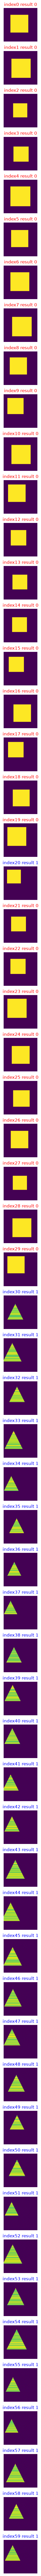

In [9]:
# 60行1列のサブプロットを作成
fig, axes = plt.subplots(60, 1, figsize=(100, 100))

# 60枚の画像を順番に表示
for i in range(60):
    ax = axes[i]

    # 画像を表示
    ax.imshow(loaded_arr[i])

    # クラスタ番号（0 または 1）
    c = cluster[i]

    # クラスタ番号によってタイトルの色を変更
    color = "red" if c == 0 else "blue"

    # インデックス番号とクラスタ番号を表示
    ax.set_title(
        f'index{i} result {c}',
        color=color
    )

    # x・y軸を非表示
    ax.axis("off")

plt.tight_layout()
plt.show()

<br>

##### ※ 画像クラスタリングのポイント

- 四角形・三角形の画像クラスタリングでは、画像を**ピクセル値の数値データに変換**し、K-Meansを用いて似た画像同士をグループ化した。

- 犬や猫の画像も原理は同じで、コンピュータが扱えるように**画像を数値データへ変換する必要がある**。

- しかし、四角形や三角形のような単純な画像はピクセル値だけでも区別しやすいが、**犬や猫のような複雑な画像ではピクセル値だけでの分類は難しい**。

- そのため、CNNなどの深層学習モデルを用いて**画像の特徴を数値データとして抽出**し、その特徴量にK-Meansを適用してクラスタリングする。

→ `画像を数値データに変換してクラスタリングすることが基本である。`<br>
`だが、複雑な画像ほど、特徴量を効果的に抽出する処理が重要だ。`

<div style="display:inline-block; min-width:760px; font-family:Consolas, 'Yu Gothic', monospace; line-height:30px; margin:4px 0 14px 0; color:#222;"><div style="background:#f4f5f6; padding:0 16px;">&nbsp;</div><div style="background:#e7e9eb; padding:0 16px;"><strong>画像</strong></div><div style="background:#f4f5f6; padding:0 16px;">↓</div><div style="background:#e7e9eb; padding:0 16px;"><strong><span style="color:#ff5a1f;">数値データへ変換</span></strong></div><div style="background:#f4f5f6; padding:0 16px;">↓</div><div style="background:#e7e9eb; padding:0 16px;"><strong><span style="color:#ff5a1f;">特徴量を抽出</span></strong></div><div style="background:#f4f5f6; padding:0 16px;">↓</div><div style="background:#e7e9eb; padding:0 16px;"><strong>K-Means</strong></div><div style="background:#f4f5f6; padding:0 16px;">↓</div><div style="background:#e7e9eb; padding:0 16px;"><strong>類似した画像をクラスタリング</strong></div></div>

<br>

### 【実習 2】Irisデータを用いたK-Meansクラスタリング

Irisデータセットから**正解ラベル（3クラス）を除外**し、`K=3`としてK-Meansによる教師なしクラスタリングを行う。

<br>

#### ※ クラスタ数 `K` の決め方

- K-Meansでは、データを<strong>何個のグループに分けるか（K）</strong>を決める必要がある。

- しかし、教師なし学習では正解がないため、最初から最適なKが分からないことが多い。

- そこで、**Kを2、3、4、5…と変えながら何度かK-Meansを実行**し、グループ内のデータがどのくらいまとまっているかを確認する。

<br>


<img src="../images/image-76_2.png" width="500">

- Kを増やしながらK-Meansを繰り返す
- **同じグループ内のデータがどのくらい近くまとまっているか**を確認
- グラフの下がり方が急から緩やかに変わる地点を探す
- その地点のKを、クラスタ数の候補として選ぶ

<br>

#### ① ライブラリの読み込み

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

<br>

#### ② Irisデータの読み込み

`as_frame=True` を指定し、Irisデータを**PandasのDataFrame形式**で読み込む。

今回は教師なし学習のため、正解ラベル（target）は使用せず、花の特徴データだけを `X` に保存する。

In [13]:
iris = load_iris(as_frame=True)

# 花の特徴データのみを使用（正解ラベル target は除外）
X = iris.data

display(X.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


- sepal length：がく片の長さ
- sepal width：がく片の幅
- petal length：花びらの長さ
- petal width：花びらの幅

<br>

#### ③ 散布図でデータの分布を確認

各特徴量の組み合わせを散布図で表示し、**データがどのように分かれているか**を確認する。

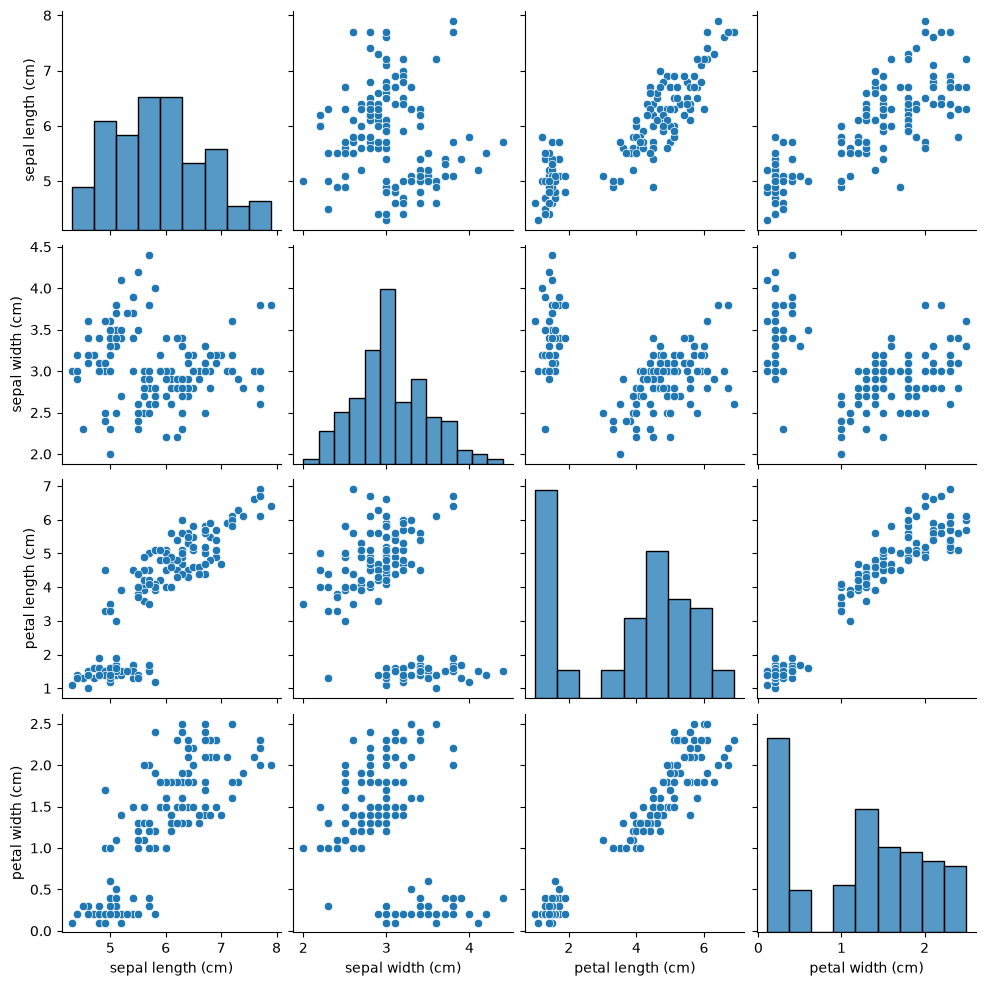

In [ ]:
# 複数の特徴量を組み合わせて散布図を表示し、データの分布や関係をまとめて確認する。
sns.pairplot(X) 

<br>

#### ④ データの標準化

各特徴量の数値の大きさをそろえるため、`StandardScaler`を用いて標準化する。

→ **平均0・標準偏差1**を基準とした値に変換

In [18]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

<br>

#### ⑤ K-Meansによるクラスタリング

標準化したデータをK-Meansに入力し、**3つのクラスタ**に分ける。

In [ ]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10 # 初期位置を変えて10回実行し、その中から良い結果を使用
)

cluster = kmeans.fit_predict(X_scaled)

<br>

#### ⑥ クラスタリング結果と正解ラベルの確認

K-Meansが自動で付けたクラスタ番号と、Irisデータに元から入っている正解ラベルを確認する。

In [21]:
# K-Meansが自動で付けたクラスタ番号
print(cluster)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


<br>

In [22]:
# 正解ラベルのデータ型を確認
print(type(iris.target))

<class 'pandas.Series'>


<br>

In [ ]:
#Irisデータの正解ラベルをNumPy配列として確認
print(iris.target.to_numpy())

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


<br>

→ K-Meansの0・1・2は単なるグループ番号のため、正解ラベルの0・1・2と同じ番号になるとは限らない。